In [1]:
# First install the extendedjetpy package with: python setup.py install
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import JetCode # CHANGE TO extendedjetpy CUANDO ANDE BIEN!!!!

In [2]:
# Define the SED function
def model_sed(E, z, sigma0, Lj, z0, a_inj):
    #CAMBIARLO A keyword arguments! Menos chances de errores
    """
    Total (Synchrotron + SSC) SED calculated at photon energies in the vector E
    at integration heights z.
    The available free parameters are: 
    - sigma0 (initial magnetization) 
    - Lj (jet luminosity)
    - z0 (height at jet base)
    - a_inj (power injected as Q(z) \propto z^-a_inj)
    """
    # CHANGE TO extendedjetpy CUANDO ANDE BIEN!!!!
    
    # This routine returns m_data_max values, as defined in global.f90
    fit_values = JetCode.sed_model(sigma0, Lj, z0, a_inj, E, z) 
    
    # The only useful values are the first ones up to the number of points in E
    return( fit_values[:len(E)])     

In [3]:
#Constants
mJy = 1.0e-26
dist = 16.8*3.0856e24  # Distance to the source = 16.8 Mpc
h = 6.6260755e-27      # erg s
eV = 1.602176e-12      # eV to erg
a = 4.0*np.pi*dist**2  # Flux dilution factor
M_BH = 6.5e9           # Black hole mass [Msun] (EHT+2018?)
R_g = 1.477e5*M_BH     # Gravitational radius (M_BH [Msun])

# Default model parameters
sigma0 = 1e1
Lj = 1e43
z0 = 10.0*R_g
a_inj = 1.00001

# Define the energy range for the SED
E_min = 1.e-7 * eV #Aprox 20 MHz
E_max = 1.e10 * eV
n_points = 80
E = np.geomspace(E_min, E_max, n_points)
z = np.geomspace(5*R_g, 100*R_g, n_points)

# Explore sigma0 variations

In [ ]:
# Make a list with the values of fB 
sigma0s = [1e-4, 1e-3, 1e-2, 1e-1] 

# Calculate the SED for each fB (fixing default parameters)
SEDs = []
for sigma0 in sigma0s:
    SED = model_sed(E, z, sigma0, Lj, z0, a_inj)
    SEDs.append(SED)

In [ ]:
# Voy a graficar datos y modelo
fig, ax = plt.subplots(1)

# Defino una paleta discreta
n = len(fBs)
color_vector = np.linspace(0.2, 0.9, n)
colors = plt.cm.copper_r(color_vector) # define a palette avoiding extreme colors
# Genero una colorbar discreta para n puntos
c = np.arange(1, n+1) 
cmap = plt.cm.get_cmap('copper_r', n)
norm = matplotlib.colors.BoundaryNorm(np.arange(n+1)+0.5,n)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# Definiciones estéticas
nice_fonts = {
        # Use LaTeX to write all text
        "text.usetex": True,
        "font.family": 'serif',
        # Use 10pt font in plots, to match 10pt font in document
        "axes.labelsize": 18,
        "font.size": 18,
        "axes.linewidth":1,
        "axes.titlesize":16,
        # Make the legend/label fonts a little smaller
        "legend.fontsize": 12,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "xtick.major.size": 5,     # major tick size in points
        "xtick.minor.size": 5,       # minor tick size in points
        "xtick.major.width": 1.4,     # major tick width in points
        "xtick.minor.width": 1.4,     # minor tick width in points
}
matplotlib.rcParams.update(nice_fonts)

# Set labels
plt.title('')
plt.setp(ax, xlabel=r"$E$ [eV]")
plt.setp(ax, ylabel=r"$E \times L_E$ [erg s$^{-1}$]")

# Set plot scales
xmin, xmax = E_min/eV, E_max/eV
ymin, ymax = 1e35, 1e42
plt.xlim(xmin, xmax)
plt.ylim(ymin, ymax)

# Grafico las funciones individuales y su suma usando una paleta discreta
for i in range(n):
    plt.plot(E/eV, E*SEDs[i]*a, ls='-', color=colors[i], linewidth=2, label='', zorder=1)

plt.legend(loc='best')
ax.loglog() 

cbar = fig.colorbar(sm, ticks=c, label=r"$\sigma_0$", pad=0.015)
cbar.ax.set_yticklabels(sigma0s)  # vertically oriented colorbar

# Set xticks
num = int(np.log10(xmax/xmin))
x_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = num//2)
ax.xaxis.set_major_locator(x_major)
x_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = (num//2) * 3)
ax.xaxis.set_minor_locator(x_minor)
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

# Set yticks
numy = int(np.log10(ymax/ymin))
y_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy//2+1)
ax.yaxis.set_major_locator(y_major)
y_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy+2)
ax.yaxis.set_minor_locator(y_minor)
ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

plt.show()

#fig.tight_layout(pad=0)
#fig.savefig('SEDs_etas.pdf', bbox_inches='tight', pad_inches = 0.01)
#AJUSTO A MANO EL RECORTE
fig.subplots_adjust(bottom=0.16, top=0.97, left=0.14, right=0.91)
fig.savefig('SEDs_sigma0s.pdf')

# Explore Ljet variations

In [ ]:
# Make a list with the values of Lj 
Ljs = [1e42, 3.3e42, 1e43, 3.3e43] 

# Calculate the SED for each Lj (fixing default parameters)
SEDs = []
for Lj in Ljs:
    SED = model_sed(E, z, fB, Lj, z0, a_inj)
    SEDs.append(SED)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


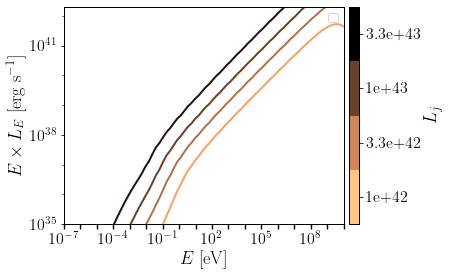

In [28]:
# Voy a graficar datos y modelo
fig, ax = plt.subplots(1)

# Defino una paleta discreta
n = len(Ljs)
color_vector = np.linspace(0.2, 0.9, n)
colors = plt.cm.copper_r(color_vector) # define a palette avoiding extreme colors
# Genero una colorbar discreta para n puntos
c = np.arange(1, n+1) 
cmap = plt.cm.get_cmap('copper_r', n)
norm = matplotlib.colors.BoundaryNorm(np.arange(n+1)+0.5,n)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# Definiciones estéticas
nice_fonts = {
        # Use LaTeX to write all text
        "text.usetex": True,
        "font.family": 'serif',
        # Use 10pt font in plots, to match 10pt font in document
        "axes.labelsize": 18,
        "font.size": 18,
        "axes.linewidth":1,
        "axes.titlesize":16,
        # Make the legend/label fonts a little smaller
        "legend.fontsize": 12,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "xtick.major.size": 5,     # major tick size in points
        "xtick.minor.size": 5,       # minor tick size in points
        "xtick.major.width": 1.4,     # major tick width in points
        "xtick.minor.width": 1.4,     # minor tick width in points
}
matplotlib.rcParams.update(nice_fonts)

# Set labels
plt.title('')
plt.setp(ax, xlabel=r"$E$ [eV]")
plt.setp(ax, ylabel=r"$E \times L_E$ [erg s$^{-1}$]")

# Set plot scales
xmin, xmax = E_min/eV, E_max/eV
ymin, ymax = 1e35, 2e42
plt.xlim(xmin, xmax)
plt.ylim(ymin, ymax)

# Grafico las funciones individuales y su suma usando una paleta discreta
for i in range(n):
    plt.plot(E/eV, E*SEDs[i]*a, ls='-', color=colors[i], linewidth=2, label='', zorder=1)

plt.legend(loc='best')
ax.loglog() 

cbar = fig.colorbar(sm, ticks=c, label=r"$L_j$", pad=0.015)
cbar.ax.set_yticklabels(Ljs)  # vertically oriented colorbar

# Set xticks
num = int(np.log10(xmax/xmin))
x_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = num//2)
ax.xaxis.set_major_locator(x_major)
x_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = (num//2) * 3)
ax.xaxis.set_minor_locator(x_minor)
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

# Set yticks
numy = int(np.log10(ymax/ymin))
y_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy//2+1)
ax.yaxis.set_major_locator(y_major)
y_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy+2)
ax.yaxis.set_minor_locator(y_minor)
ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

plt.show()

#fig.tight_layout(pad=0)
#fig.savefig('SEDs_etas.pdf', bbox_inches='tight', pad_inches = 0.01)
#AJUSTO A MANO EL RECORTE
fig.subplots_adjust(bottom=0.16, top=0.97, left=0.14, right=0.89)
fig.savefig('SEDs_Ljs.pdf')

# Explore z0 variations

In [29]:
# Make a list with the values of z0 in units of R_g
z0s = [1.0, 2.0, 4.0, 8.0]

# Calculate the SED for each z0 (fixing default parameters)
SEDs = []
for z0 in z0s:
    SED = model_sed(E, z, fB, Lj, z0*R_g, a_inj)
    SEDs.append(SED)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


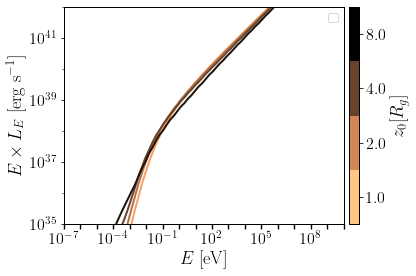

In [30]:
# Voy a graficar datos y modelo
fig, ax = plt.subplots(1)

# Defino una paleta discreta
n = len(z0s)
color_vector = np.linspace(0.2, 0.9, n)
colors = plt.cm.copper_r(color_vector) # define a palette avoiding extreme colors
# Genero una colorbar discreta para n puntos
c = np.arange(1, n+1) 
cmap = plt.cm.get_cmap('copper_r', n)
norm = matplotlib.colors.BoundaryNorm(np.arange(n+1)+0.5,n)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# Definiciones estéticas
nice_fonts = {
        # Use LaTeX to write all text
        "text.usetex": True,
        "font.family": 'serif',
        # Use 10pt font in plots, to match 10pt font in document
        "axes.labelsize": 18,
        "font.size": 18,
        "axes.linewidth":1,
        "axes.titlesize":16,
        # Make the legend/label fonts a little smaller
        "legend.fontsize": 12,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "xtick.major.size": 5,     # major tick size in points
        "xtick.minor.size": 5,       # minor tick size in points
        "xtick.major.width": 1.4,     # major tick width in points
        "xtick.minor.width": 1.4,     # minor tick width in points
}
matplotlib.rcParams.update(nice_fonts)

# Set labels
plt.title('')
plt.setp(ax, xlabel=r"$E$ [eV]")
plt.setp(ax, ylabel=r"$E \times L_E$ [erg s$^{-1}$]")

# Set plot scales
xmin, xmax = E_min/eV, E_max/eV
ymin, ymax = 1e35, 1e42
plt.xlim(xmin, xmax)
plt.ylim(ymin, ymax)

# Grafico las funciones individuales y su suma usando una paleta discreta
for i in range(n):
    plt.plot(E/eV, E*SEDs[i]*a, ls='-', color=colors[i], linewidth=2, label='', zorder=1)

plt.legend(loc='best')
ax.loglog() 

cbar = fig.colorbar(sm, ticks=c, label=r"$z_0 [R_g]$ ", pad=0.015)
cbar.ax.set_yticklabels(z0s)  # vertically oriented colorbar

# Set xticks
num = int(np.log10(xmax/xmin))
x_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = num//2)
ax.xaxis.set_major_locator(x_major)
x_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = (num//2) * 3)
ax.xaxis.set_minor_locator(x_minor)
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

# Set yticks
numy = int(np.log10(ymax/ymin))
y_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy//2+1)
ax.yaxis.set_major_locator(y_major)
y_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy+2)
ax.yaxis.set_minor_locator(y_minor)
ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

plt.show()

#fig.tight_layout(pad=0)
#fig.savefig('SEDs_etas.pdf', bbox_inches='tight', pad_inches = 0.01)
#AJUSTO A MANO EL RECORTE
fig.subplots_adjust(bottom=0.16, top=0.97, left=0.14, right=0.96)
fig.savefig('SEDs_z0s.pdf')

# Explore a_inj variations

In [12]:
# Make a list with the values of a_inj 
a_injs = [1.1, 1.5, 2.0, 3.0] 
a_inj_labels = [1.1, 1.5, 2.0, 3.0] 

# Calculate the SED for each a_inj (fixing default parameters)
SEDs = []
for a_inj in a_injs:
    SED = model_sed(E, z, fB, Lj, z0, a_inj)
    SEDs.append(SED)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


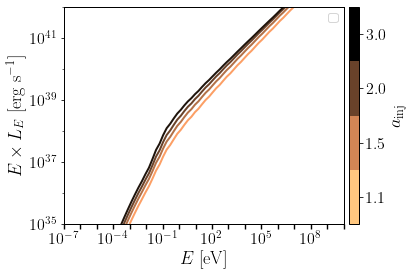

In [13]:
# Voy a graficar datos y modelo
fig, ax = plt.subplots(1)

# Defino una paleta discreta
n = len(a_injs)
color_vector = np.linspace(0.2, 0.9, n)
colors = plt.cm.copper_r(color_vector) # define a palette avoiding extreme colors
# Genero una colorbar discreta para n puntos
c = np.arange(1, n+1) 
cmap = plt.cm.get_cmap('copper_r', n)
norm = matplotlib.colors.BoundaryNorm(np.arange(n+1)+0.5,n)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# Definiciones estéticas
nice_fonts = {
        # Use LaTeX to write all text
        "text.usetex": True,
        "font.family": 'serif',
        # Use 10pt font in plots, to match 10pt font in document
        "axes.labelsize": 18,
        "font.size": 18,
        "axes.linewidth":1,
        "axes.titlesize":16,
        # Make the legend/label fonts a little smaller
        "legend.fontsize": 12,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "xtick.major.size": 5,     # major tick size in points
        "xtick.minor.size": 5,       # minor tick size in points
        "xtick.major.width": 1.4,     # major tick width in points
        "xtick.minor.width": 1.4,     # minor tick width in points
}
matplotlib.rcParams.update(nice_fonts)

# Set labels
plt.title('')
plt.setp(ax, xlabel=r"$E$ [eV]")
plt.setp(ax, ylabel=r"$E \times L_E$ [erg s$^{-1}$]")

# Set plot scales
xmin, xmax = E_min/eV, E_max/eV
ymin, ymax = 1e35, 1e42
plt.xlim(xmin, xmax)

plt.ylim(ymin, ymax)

# Grafico las funciones individuales y su suma usando una paleta discreta
for i in range(n):
    plt.plot(E/eV, E*SEDs[i]*a, ls='-', color=colors[i], linewidth=2, label='', zorder=1)

plt.legend(loc='best')
ax.loglog() 

cbar = fig.colorbar(sm, ticks=c, label=r"$a_\mathrm{inj}$", pad=0.015)
cbar.ax.set_yticklabels(a_inj_labels)  # vertically oriented colorbar

# Set xticks
num = int(np.log10(xmax/xmin))
x_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = num//2)
ax.xaxis.set_major_locator(x_major)
x_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = (num//2) * 3)
ax.xaxis.set_minor_locator(x_minor)
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

# Set yticks
numy = int(np.log10(ymax/ymin))
y_major = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy//2+1)
ax.yaxis.set_major_locator(y_major)
y_minor = matplotlib.ticker.LogLocator(base = 10.0, numticks = numy+2)
ax.yaxis.set_minor_locator(y_minor)
ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

plt.show()

#fig.tight_layout(pad=0)
#fig.savefig('SEDs_etas.pdf', bbox_inches='tight', pad_inches = 0.01)
#AJUSTO A MANO EL RECORTE
fig.subplots_adjust(bottom=0.16, top=0.97, left=0.14, right=0.97)
fig.savefig('SEDs_a_injs.pdf')